# Treinamento do classificador de movimentos
Pipeline: **CSV de pontos do corpo → janelas de ~1,5 s → features → RandomForest → modelo salvo**.

Classes: `0 normal`, `1 repetitivo`, `2 brusco`, `3 golpe_cabeca`.
Rode a partir da raiz do projeto (`python treinamento/treino.py`) ou abra este notebook em `treinamento/`.

Arquivo: dataset.csv | linhas: 2807 | sessões: 2
label
normal        1972
repetitivo     835
Name: count, dtype: int64
AVISO: só 2 sessão(ões). Dividindo por blocos de 10 s. O ideal é gravar em várias sessões diferentes.
Janelas: (133, 68) | grupos: 10
  normal        86 janelas
  repetitivo    47 janelas
Grupos de treino: 7 | grupos de teste: 3
              precision    recall  f1-score   support

      normal       0.64      0.58      0.61        24
  repetitivo       0.50      0.56      0.53        18

    accuracy                           0.57        42
   macro avg       0.57      0.57      0.57        42
weighted avg       0.58      0.57      0.57        42



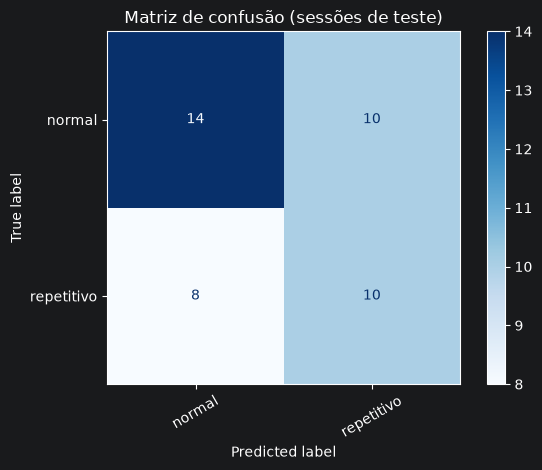

Validação cruzada por grupo (5 partes): 0.752 ± 0.046
amp_ombro_e_x          0.123736
std_ombro_e_x          0.115639
velmed_ombro_e         0.069736
amp_cotovelo_e_x       0.039927
velmax_ombro_e         0.035059
amp_ombro_e_y          0.034853
inversoes_pulso_e_x    0.025044
std_ombro_e_y          0.022976
std_nariz_x            0.019393
std_cotovelo_e_x       0.018488
velmed_pulso_e         0.016842
amp_nariz_x            0.015767
amp_tornozelo_e_x      0.015136
amp_pulso_e_x          0.014800
amp_pulso_e_y          0.014723
dtype: float64


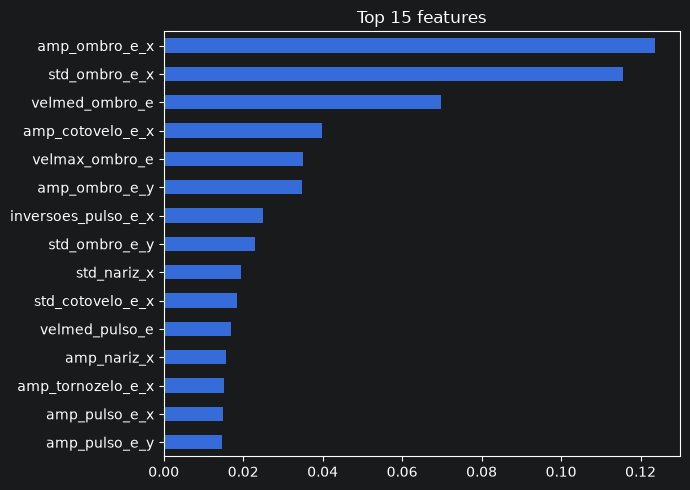

Modelo salvo em: C:\Users\asmat\Downloads\camera-inteligente\camera-inteligente\modelos\modelo_movimento.joblib
Métricas salvas em: C:\Users\asmat\Downloads\camera-inteligente\camera-inteligente\testes\metricas_treino.txt


In [1]:
# %% [markdown]
# # Treinamento do classificador de movimentos
# Pipeline: **CSV de pontos do corpo → janelas de ~1,5 s → features → RandomForest → modelo salvo**.
#
# Classes: `0 normal`, `1 repetitivo`, `2 brusco`, `3 golpe_cabeca`.
# Rode a partir da raiz do projeto (`python treinamento/treino.py`) ou abra este notebook em `treinamento/`.

# %%
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_score

RAIZ = Path.cwd()
if not (RAIZ / "pc").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "pc"))

import config
from features import features, NOMES_FEATURES, NOMES_COLUNAS

# %% [markdown]
# ## 1. Carregar os dados
# Usa `dados/dataset.csv` (gravado por vocês com `coleta.py`). Se não existir, usa o dataset **sintético**,
# que só serve para testar o pipeline.

# %%
if config.DATASET.exists():
    arquivo, sintetico = config.DATASET, False
else:
    arquivo, sintetico = config.DATASET_SINTETICO, True
    print("AVISO: dataset real não encontrado. Usando o SINTÉTICO (apenas para testar o pipeline).")

df = pd.read_csv(arquivo)
print("Arquivo:", arquivo.name, "| linhas:", len(df), "| sessões:", df["sessao"].nunique())
print(df["label"].map(dict(enumerate(config.CLASSES))).value_counts())
if df["label"].nunique() < 2:
    raise SystemExit("ERRO: o dataset tem só uma classe. Grave pelo menos 'normal' e uma classe anormal com coleta.py.")

# %% [markdown]
# ## 2. Criar janelas e calcular as features
# Cada janela tem `JANELA` frames seguidos, da **mesma classe**. Janelas com buracos de tempo
# (gravação pausada) são descartadas.
#
# Para medir o modelo de forma honesta, treino e teste não podem misturar trechos da mesma gravação.
# - Com **3 ou mais sessões**, cada sessão é um grupo.
# - Com **menos sessões** (ex.: uma gravação só), cada grupo é um **bloco de 10 s**, e janelas que
#   atravessam dois blocos são descartadas para não vazar dados entre treino e teste.

# %%
BLOCO_S = 10.0
poucas_sessoes = df["sessao"].nunique() < 3
if poucas_sessoes:
    print(f"AVISO: só {df['sessao'].nunique()} sessão(ões). Dividindo por blocos de {BLOCO_S:.0f} s. "
          "O ideal é gravar em várias sessões diferentes.")

X, y, grupos = [], [], []
for sessao, d in df.groupby("sessao"):
    d = d.sort_values("t")
    t = d["t"].to_numpy()
    lab = d["label"].to_numpy()
    dados = d[NOMES_COLUNAS].to_numpy()
    for i in range(0, len(d) - config.JANELA + 1, config.PASSO):
        s_ = slice(i, i + config.JANELA)
        if len(set(lab[s_])) != 1 or np.ptp(t[s_]) > 3.0:
            continue
        if poucas_sessoes:
            b0 = int((t[s_.start] - t[0]) // BLOCO_S)
            b1 = int((t[s_.stop - 1] - t[0]) // BLOCO_S)
            if b0 != b1:
                continue
            grupo = f"{sessao}_{b0}"
        else:
            grupo = str(sessao)
        X.append(features(dados[s_], t[s_]))
        y.append(lab[s_][0])
        grupos.append(grupo)

X, y, grupos = np.array(X), np.array(y), np.array(grupos)
n_grupos = len(set(grupos))
print("Janelas:", X.shape, "| grupos:", n_grupos)
for c in sorted(set(y)):
    print(f"  {config.CLASSES[c]:<13} {np.sum(y == c)} janelas")
if len(X) < 20 or n_grupos < 2:
    raise SystemExit("ERRO: poucos dados. Grave mais tempo (alguns minutos por classe, em mais de uma sessão).")

# %% [markdown]
# ## 3. Separar treino e teste **por grupo**
# Grupos inteiros ficam de um lado só, mantendo as classes balanceadas nos dois lados.

# %%
n_div = min(4, n_grupos)
tr, te = next(StratifiedGroupKFold(n_splits=n_div, shuffle=True, random_state=42).split(X, y, grupos))
print("Grupos de treino:", len(set(grupos[tr])), "| grupos de teste:", len(set(grupos[te])))
faltam = set(y) - set(y[tr])
if faltam:
    print("AVISO: classes ausentes no treino:", [config.CLASSES[c] for c in faltam])

# %% [markdown]
# ## 4. Treinar

# %%
modelo = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                random_state=42, n_jobs=-1)
modelo.fit(X[tr], y[tr])

# %% [markdown]
# ## 5. Avaliar (dados de sessões que o modelo não viu)

# %%
pred = modelo.predict(X[te])
rotulos = sorted(set(y))
nomes = [config.CLASSES[c] for c in rotulos]
relatorio = classification_report(y[te], pred, labels=rotulos, target_names=nomes, zero_division=0)
print(relatorio)

cm = confusion_matrix(y[te], pred, labels=rotulos)
ConfusionMatrixDisplay(cm, display_labels=nomes).plot(cmap="Blues", xticks_rotation=30)
plt.title("Matriz de confusão (sessões de teste)")
plt.tight_layout()
plt.show()

n_sessoes = df["sessao"].nunique()
if n_grupos >= 3:
    k = min(5, n_grupos)
    cv = cross_val_score(RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1),
                         X, y, groups=grupos, cv=GroupKFold(n_splits=k))
    print(f"Validação cruzada por grupo ({k} partes): {cv.mean():.3f} ± {cv.std():.3f}")

# %% [markdown]
# ## 6. Quais features mais importam

# %%
imp = pd.Series(modelo.feature_importances_, index=NOMES_FEATURES).sort_values(ascending=False)
print(imp.head(15))
imp.head(15)[::-1].plot.barh(figsize=(7, 5), title="Top 15 features")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 7. Salvar o modelo final
# O modelo de produção é treinado com **todas** as janelas (a avaliação acima já foi feita nas sessões separadas).

# %%
modelo_final = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                      random_state=42, n_jobs=-1).fit(X, y)
config.MODELO_CLASSIFICADOR.parent.mkdir(exist_ok=True)
joblib.dump(modelo_final, config.MODELO_CLASSIFICADOR)
print("Modelo salvo em:", config.MODELO_CLASSIFICADOR)

# guarda o relatório para anexar na entrega
metricas = RAIZ / "testes" / "metricas_treino.txt"
metricas.parent.mkdir(exist_ok=True)
metricas.write_text(
    f"Dataset: {arquivo.name} ({'SINTÉTICO - só teste do pipeline' if sintetico else 'real'})\n"
    f"Janelas: {len(X)} | sessões: {n_sessoes}\n\n{relatorio}\nMatriz de confusão:\n{cm}\n",
    encoding="utf-8")
print("Métricas salvas em:", metricas)

## 1. Carregar os dados
Usa `dados/dataset.csv` (gravado por vocês com `coleta.py`). Se não existir, usa o dataset **sintético**,
que só serve para testar o pipeline.

In [2]:
if config.DATASET.exists():
    arquivo, sintetico = config.DATASET, False
else:
    arquivo, sintetico = config.DATASET_SINTETICO, True
    print("AVISO: dataset real não encontrado. Usando o SINTÉTICO (apenas para testar o pipeline).")

df = pd.read_csv(arquivo)
print("Arquivo:", arquivo.name, "| linhas:", len(df), "| sessões:", df["sessao"].nunique())
print(df["label"].map(dict(enumerate(config.CLASSES))).value_counts())

Arquivo: dataset.csv | linhas: 2807 | sessões: 2
label
normal        1972
repetitivo     835
Name: count, dtype: int64


## 2. Criar janelas e calcular as features
Cada janela tem `JANELA` frames seguidos, da **mesma sessão** e da **mesma classe**.
Janelas com buracos de tempo (gravação pausada) são descartadas.

In [3]:
X, y, grupos = [], [], []
for sessao, d in df.groupby("sessao"):
    d = d.sort_values("t")
    t = d["t"].to_numpy()
    lab = d["label"].to_numpy()
    dados = d[NOMES_COLUNAS].to_numpy()
    for i in range(0, len(d) - config.JANELA + 1, config.PASSO):
        s = slice(i, i + config.JANELA)
        if len(set(lab[s])) != 1:
            continue
        if np.ptp(t[s]) > 3.0:
            continue
        X.append(features(dados[s], t[s]))
        y.append(lab[s][0])
        grupos.append(sessao)

X, y, grupos = np.array(X), np.array(y), np.array(grupos)
print("Janelas:", X.shape, "| por classe:", np.bincount(y))

Janelas: (154, 68) | por classe: [101  53]


## 3. Separar treino e teste **por sessão**
Janelas da mesma gravação nunca ficam dos dois lados; assim o teste mede como o modelo se sai em gravações novas.

In [4]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(X, y, grupos))
print("Sessões de treino:", len(set(grupos[tr])), "| sessões de teste:", len(set(grupos[te])))

NameError: name 'GroupShuffleSplit' is not defined

## 4. Treinar

In [ ]:
modelo = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                random_state=42, n_jobs=-1)
modelo.fit(X[tr], y[tr])

## 5. Avaliar (dados de sessões que o modelo não viu)

In [ ]:
pred = modelo.predict(X[te])
nomes = [config.CLASSES[c] for c in sorted(set(y))]
relatorio = classification_report(y[te], pred, target_names=nomes, zero_division=0)
print(relatorio)

cm = confusion_matrix(y[te], pred)
ConfusionMatrixDisplay(cm, display_labels=nomes).plot(cmap="Blues", xticks_rotation=30)
plt.title("Matriz de confusão (sessões de teste)")
plt.tight_layout()
plt.show()

n_sessoes = len(set(grupos))
if n_sessoes >= 3:
    k = min(5, n_sessoes)
    cv = cross_val_score(RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1),
                         X, y, groups=grupos, cv=GroupKFold(n_splits=k))
    print(f"Validação cruzada por sessão ({k} partes): {cv.mean():.3f} ± {cv.std():.3f}")

## 6. Quais features mais importam

In [ ]:
imp = pd.Series(modelo.feature_importances_, index=NOMES_FEATURES).sort_values(ascending=False)
print(imp.head(15))
imp.head(15)[::-1].plot.barh(figsize=(7, 5), title="Top 15 features")
plt.tight_layout()
plt.show()

## 7. Salvar o modelo final
O modelo de produção é treinado com **todas** as janelas (a avaliação acima já foi feita nas sessões separadas).

In [ ]:
modelo_final = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                      random_state=42, n_jobs=-1).fit(X, y)
config.MODELO_CLASSIFICADOR.parent.mkdir(exist_ok=True)
joblib.dump(modelo_final, config.MODELO_CLASSIFICADOR)
print("Modelo salvo em:", config.MODELO_CLASSIFICADOR)

# guarda o relatório para anexar na entrega
metricas = RAIZ / "testes" / "metricas_treino.txt"
metricas.parent.mkdir(exist_ok=True)
metricas.write_text(
    f"Dataset: {arquivo.name} ({'SINTÉTICO - só teste do pipeline' if sintetico else 'real'})\n"
    f"Janelas: {len(X)} | sessões: {n_sessoes}\n\n{relatorio}\nMatriz de confusão:\n{cm}\n",
    encoding="utf-8")
print("Métricas salvas em:", metricas)